In [19]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [20]:
df = pd.read_csv('DistancesCNO.csv')
print(df)

    Group  Total Distance Control
0       1           11.79       y
1       2           10.10       y
2       3           14.77       y
3       4           11.42       y
4       5            7.36       y
5       6            9.60       y
6       7           14.09       y
7       8           14.21       y
8       9           13.47       y
9      10            3.22       y
10     11            7.14       y
11     12           13.98       y
12     13            8.45       y
13     14            8.85       y
14     15           11.64       y
15     16            9.35       y
16     17            5.43       y
17     18           13.07       y
18     19            8.77       y
19     20           13.34       y
20     21           14.71       n
21     22           14.19       n
22     23            6.76       n
23     24           12.77       n
24     25           12.41       n
25     26            9.59       n
26     27           14.15       n
27     28            6.94       n
28     29     

In [21]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_53721/1616282542.py:22: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  ax = sns.stripplot(
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


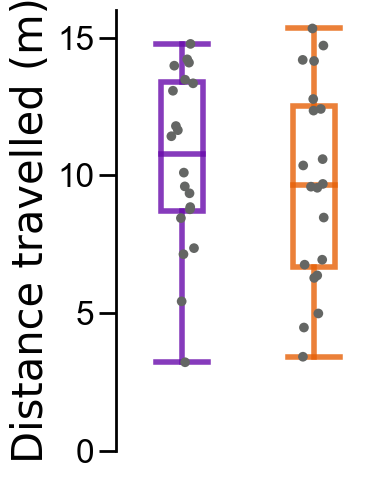

In [22]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']

text_boxplot = ['','***']
colors = ["#646664","#646664"]

colors_boxplot = ['#078f4f', "#680aab"]
colors_boxplot = ["#680aab", '#e66007']



colors_boxplot_filling = ['#aba9a9',"#aba9a9"]
colors_boxplot_filling = ['none',"none"]


ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    size=7,
    y='Left preference',
    x='control',
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)
#plt.axhline(linewidth=2, color='grey',ls='--')


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

ax.set_ylim([0,16])

plt.legend([],[], frameon=False)
#ax.set_xticks([1,4,7])
#ax.set_xticklabels(['Social 1','Social 2','Recall'], fontsize = 26)
ax.set_xlabel('')
ax.set_xticks([])


ax.set_ylabel('Distance travelled (m)', fontsize = 30)
ax.set_yticks([0,5,10,15])
ax.set_yticklabels(['0','5','10','15'],fontname='Arial')


ax.tick_params(axis='y', which='major', direction='out',length=12, labelsize=24, width=2)

fig = ax.get_figure()
adjust_box_widths(fig, 0.4)
fig.set_size_inches(4,4.9)

plt.tight_layout()
fig.tight_layout()
fig.savefig("DistanceTravelledCNO.jpg",dpi=600,bbox_inches='tight')
plt.savefig('DistanceTravelledCNO.eps', dpi=600, format='eps')

